# CKA Analysis for Transformer Language Models

Compare layer representations of transformer models (BERT, GPT-2, DistilBERT) with **pytorch-cka**.

**Requirements:** `pip install pytorch-cka transformers`

To keep the notebook fast and download-free, it uses small randomly initialized models and synthetic token IDs, so it runs on a CPU in seconds. For a real analysis, load pretrained weights with `from_pretrained(...)` and use tokenized text from your dataset; the CKA calls stay the same.

In [1]:
import copy

import torch
from torch.utils.data import DataLoader, Dataset
from transformers import (
    BertConfig,
    BertModel,
    DistilBertConfig,
    DistilBertModel,
    GPT2Config,
    GPT2Model,
)

from cka import cka_from_features, compute_cka
from cka import plot_cka_comparison, plot_cka_heatmap, plot_cka_trend

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cpu


## How transformer layers are handled

- **Batches** can be dicts. pytorch-cka feeds the model the tensor under the first key it finds among `input`, `inputs`, `x`, `image`, `images`, `input_ids`, `pixel_values`; here that is `input_ids`.
- **Layer outputs**: a transformer block returns `(batch, seq_len, hidden)` (or a tuple whose first element is that tensor). The forward hook flattens it to `(batch, seq_len * hidden)`, so every token position contributes to the similarity.
- **Padding**: only `input_ids` reaches the model, with no `attention_mask`. The examples in sections 1 to 4 use equal-length sequences without padding. For padded text, use the mask-aware approach in section 5.

In [2]:
BATCH_SIZE = 8  # must be > 3 (the unbiased HSIC estimator divides by n(n-3))
NUM_SAMPLES = 32  # 4 batches
SEQ_LENGTH = 64
VOCAB_SIZE = 1000  # shared by all models below
HIDDEN = 256


class TokenDataset(Dataset):
    """Returns dict samples, like a tokenized Hugging Face dataset."""

    def __init__(self, input_ids):
        self.input_ids = input_ids

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return {"input_ids": self.input_ids[idx]}


input_ids = torch.randint(0, VOCAB_SIZE, (NUM_SAMPLES, SEQ_LENGTH))
dataloader = DataLoader(TokenDataset(input_ids), batch_size=BATCH_SIZE, shuffle=False)
print(f"{len(dataloader)} batches of {BATCH_SIZE} sequences x {SEQ_LENGTH} tokens")

4 batches of 8 sequences x 64 tokens


In [3]:
# Layer names come from model.named_modules(); these select each transformer block.
def bert_layers(model):
    return [f"encoder.layer.{i}" for i in range(model.config.num_hidden_layers)]


def gpt2_layers(model):
    return [f"h.{i}" for i in range(model.config.n_layer)]


def distilbert_layers(model):
    return [f"transformer.layer.{i}" for i in range(model.config.n_layers)]

## 1. Self-similarity

Compare every block of one BERT model with every other block.

In [4]:
bert = BertModel(
    BertConfig(
        hidden_size=HIDDEN,
        num_hidden_layers=6,
        num_attention_heads=4,
        intermediate_size=512,
        vocab_size=VOCAB_SIZE,
        max_position_embeddings=128,
    )
)
BERT_LAYERS = bert_layers(bert)

# Passing the same model twice runs a single forward pass per batch.
(bert_self_cka,) = compute_cka(bert, bert, dataloader, layers=BERT_LAYERS, device=device, progress=False)

print(f"Matrix shape: {tuple(bert_self_cka.shape)}")
print(f"Diagonal (should be 1.0): {torch.diag(bert_self_cka)}")

Matrix shape: (6, 6)
Diagonal (should be 1.0): tensor([1., 1., 1., 1., 1., 1.])


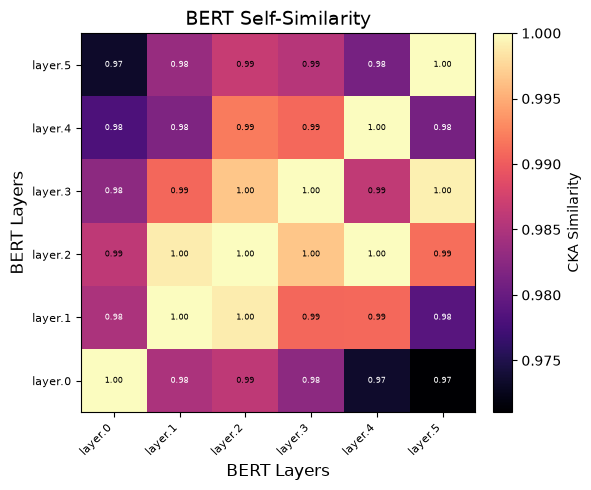

In [5]:
fig, ax = plot_cka_heatmap(
    bert_self_cka,
    layers1=BERT_LAYERS,
    layers2=BERT_LAYERS,
    model1_name="BERT",
    model2_name="BERT",
    title="BERT Self-Similarity",
    annot=True,
    layer_name_depth=2,
)

## 2. Cross-architecture comparison

Compare an encoder (BERT) with a decoder (GPT-2). The two models use different layer names, so pass the second list as `model2_layers`.

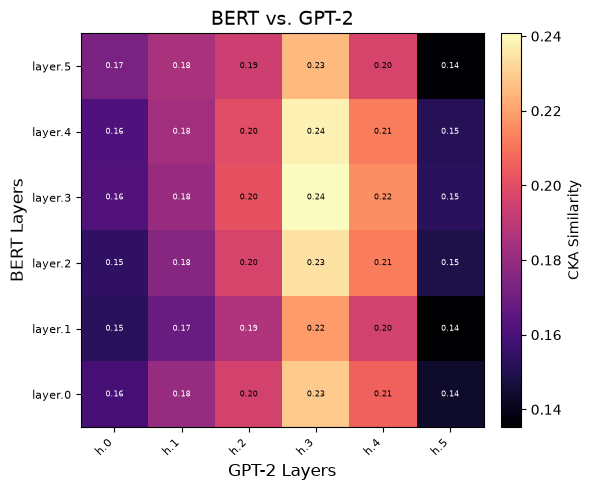

In [6]:
gpt2 = GPT2Model(GPT2Config(n_embd=HIDDEN, n_layer=6, n_head=4, vocab_size=VOCAB_SIZE, n_positions=128, bos_token_id=0, eos_token_id=0))
GPT2_LAYERS = gpt2_layers(gpt2)

(cross_arch_cka,) = compute_cka(
    bert,
    gpt2,
    dataloader,
    layers=BERT_LAYERS,
    model2_layers=GPT2_LAYERS,
    device=device,
    progress=False,
)

fig, ax = plot_cka_heatmap(
    cross_arch_cka,
    layers1=BERT_LAYERS,
    layers2=GPT2_LAYERS,
    model1_name="BERT",
    model2_name="GPT-2",
    title="BERT vs. GPT-2",
    annot=True,
    layer_name_depth=2,
)

## 3. Models of different depth

Layer counts don't have to match: compare 6-layer BERT with 3-layer DistilBERT. The result is a 6 x 3 matrix.

Matrix shape: (6, 3)


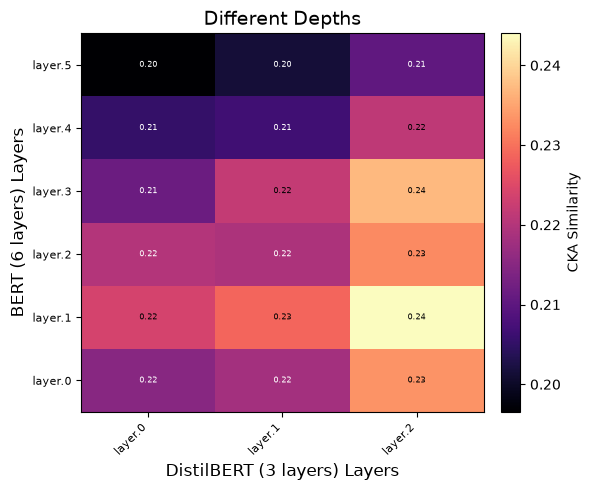

In [7]:
distilbert = DistilBertModel(
    DistilBertConfig(
        dim=HIDDEN,
        n_layers=3,
        n_heads=4,
        hidden_dim=512,
        vocab_size=VOCAB_SIZE,
        max_position_embeddings=128,
    )
)
DISTILBERT_LAYERS = distilbert_layers(distilbert)

(depth_cka,) = compute_cka(
    bert,
    distilbert,
    dataloader,
    layers=BERT_LAYERS,
    model2_layers=DISTILBERT_LAYERS,
    device=device,
    progress=False,
)
print(f"Matrix shape: {tuple(depth_cka.shape)}")

fig, ax = plot_cka_heatmap(
    depth_cka,
    layers1=BERT_LAYERS,
    layers2=DISTILBERT_LAYERS,
    model1_name="BERT (6 layers)",
    model2_name="DistilBERT (3 layers)",
    title="Different Depths",
    annot=True,
    layer_name_depth=2,
)

## 4. Before vs. after a weight change

A stand-in for fine-tuning: add noise to the weights of blocks 4 and 5 only, then compare each block with its counterpart. The diagonal of the CKA matrix shows how much each block changed.

Per-block similarity: tensor([1.0000, 1.0000, 0.9977, 1.0000, 0.0968, 0.2556])


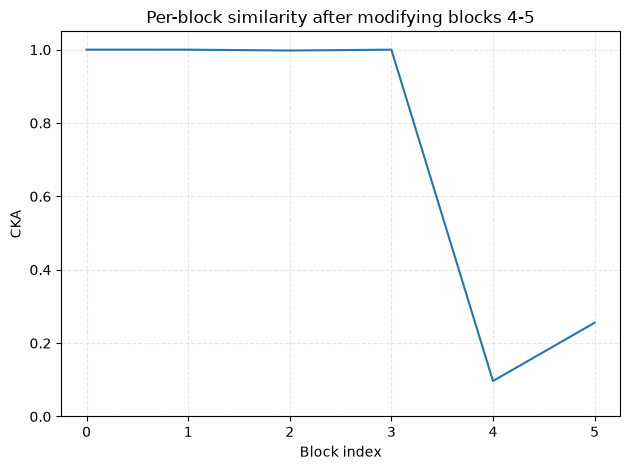

In [8]:
bert_modified = copy.deepcopy(bert)
with torch.no_grad():
    for name, param in bert_modified.named_parameters():
        if name.startswith(("encoder.layer.4.", "encoder.layer.5.")):
            param.add_(torch.randn_like(param) * 0.1)

(modified_cka,) = compute_cka(
    bert, bert_modified, dataloader, layers=BERT_LAYERS, device=device, progress=False
)
print(f"Per-block similarity: {torch.diag(modified_cka)}")

fig, ax = plot_cka_trend(
    torch.diag(modified_cka),
    labels=["Original vs. modified"],
    xlabel="Block index",
    ylabel="CKA",
    title="Per-block similarity after modifying blocks 4-5",
    legend=True,
)

## 5. Padded sequences with `cka_from_features`

Real text batches have different lengths and padding. Since `compute_cka` passes only `input_ids`, extract features yourself: run the model with its `attention_mask`, average each layer's hidden states over the real tokens only, and pass the stacked features to `cka_from_features`, which accepts a `(n_layers, n_samples, dim)` tensor per model.

BERT features: (6, 32, 256), GPT-2 features: (6, 32, 256)


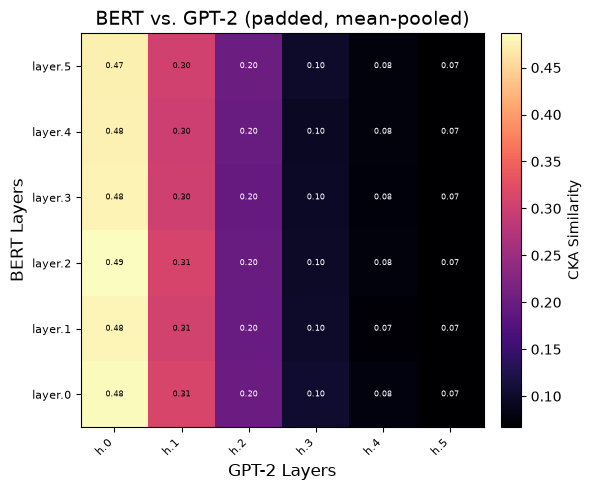

In [9]:
# Sequences of random length from 16 to 64 tokens, right-padded with token 0.
lengths = torch.randint(16, SEQ_LENGTH + 1, (NUM_SAMPLES,))
attention_mask = (torch.arange(SEQ_LENGTH)[None, :] < lengths[:, None]).long()
padded_ids = torch.randint(1, VOCAB_SIZE, (NUM_SAMPLES, SEQ_LENGTH)) * attention_mask


@torch.no_grad()
def masked_mean_features(model, input_ids, attention_mask):
    """(n_layers, n_samples, hidden): each block's output averaged over non-padding tokens."""
    model.eval()
    hidden_states = model(
        input_ids=input_ids, attention_mask=attention_mask, output_hidden_states=True
    ).hidden_states[1:]  # drop the embedding output, keep one entry per block
    mask = attention_mask[:, :, None].to(hidden_states[0].dtype)
    return torch.stack([(h * mask).sum(1) / mask.sum(1) for h in hidden_states])


bert_feats = masked_mean_features(bert, padded_ids, attention_mask)
gpt2_feats = masked_mean_features(gpt2, padded_ids, attention_mask)
print(f"BERT features: {tuple(bert_feats.shape)}, GPT-2 features: {tuple(gpt2_feats.shape)}")

padded_cka = cka_from_features(bert_feats, gpt2_feats)

fig, ax = plot_cka_heatmap(
    padded_cka,
    layers1=BERT_LAYERS,
    layers2=GPT2_LAYERS,
    model1_name="BERT",
    model2_name="GPT-2",
    title="BERT vs. GPT-2 (padded, mean-pooled)",
    annot=True,
    layer_name_depth=2,
)

`cka_from_features` computes CKA over all samples at once, so the feature tensors must fit in memory. Mean pooling compares one vector per sequence, while `compute_cka` compares every token position; pick the one that matches your question.

## Side-by-side summary

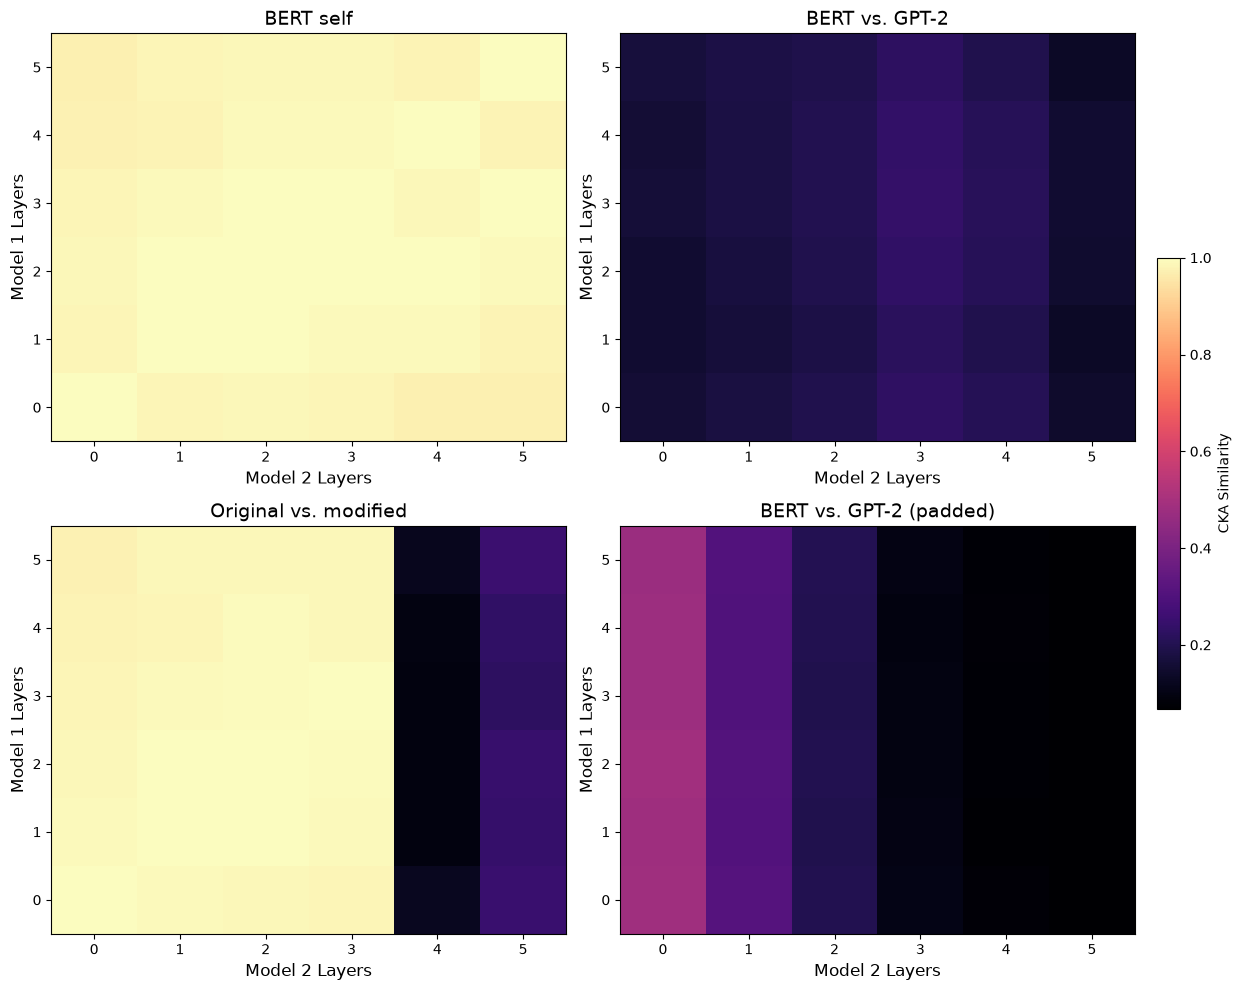

In [10]:
fig, axes = plot_cka_comparison(
    matrices=[bert_self_cka, cross_arch_cka, modified_cka, padded_cka],
    titles=["BERT self", "BERT vs. GPT-2", "Original vs. modified", "BERT vs. GPT-2 (padded)"],
    ncols=2,
    share_colorbar=True,
    figsize=(12, 10),
)

## What to look for

These models are randomly initialized and the inputs are random tokens, so the numbers above only demonstrate the API. With pretrained models and real text:

1. **Self-similarity**: the diagonal is always 1.0; neighboring blocks are usually more similar than distant ones.
2. **Cross-architecture**: blocks at similar relative depth often have the highest CKA, even across encoder and decoder designs.
3. **Different depths**: one block of a shallower model often lines up with several blocks of a deeper one.
4. **Fine-tuning**: the per-block diagonal shows where a model changed; in section 4 only blocks 4-5 drop because only they were modified.